# Monte Carlo Financial Simulation: walkthrough

Step by step: simulate paths, check them against theory, price an option with a confidence interval, see how fast the error shrinks, and show how jumps create a volatility skew.

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '../src')
from monte_carlo import *
from monte_carlo.analytics import gbm_theory
S0, r = 7136.0, 0.042

## 1. Simulate GBM paths
One year of daily steps, base case: 7% drift, 18% volatility.

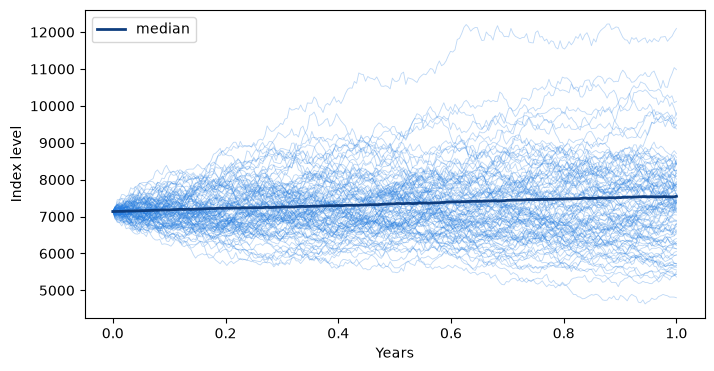

In [2]:
times, paths = simulate_gbm(S0, mu=0.07, sigma=0.18, T=1.0, n_steps=252, n_paths=10_000, seed=1)
plt.figure(figsize=(8,4))
plt.plot(times, paths[:100].T, lw=0.6, alpha=0.3, color='#257de0')
plt.plot(times, np.median(paths, axis=0), color='#0e3d7e', lw=2, label='median')
plt.xlabel('Years'); plt.ylabel('Index level'); plt.legend(); plt.show()

## 2. Check the simulation against closed-form GBM moments

In [3]:
sim = distribution_stats(paths[:, -1], S0, 1.0)
th = gbm_theory(S0, 0.07, 0.18, 1.0)
for k in ['expected_return', 'prob_loss', 'p05', 'p95']:
    print(f'{k:16s} simulated {sim[k]:7.2%}   theory {th[k]:7.2%}')

expected_return  simulated   7.48%   theory   7.25%
prob_loss        simulated  37.88%   theory  38.25%
p05              simulated -21.10%   theory -21.52%
p95              simulated  42.07%   theory  41.89%


The mean return beats the median because lognormal returns are right-skewed (the $-\sigma^2/2$ drag on the median).

## 3. Price an option with a confidence interval
The SPX Dec-18 7,200 call from Project 1, at its 23.4% implied volatility.

In [4]:
m = MARKET_CHECK
bs = black_scholes(m['S0'], m['K'], m['T'], m['r'], m['sigma'])
for method in ['plain', 'antithetic', 'control']:
    res = mc_european(m['S0'], m['K'], m['T'], m['r'], m['sigma'], n_paths=200_000, method=method, seed=2)
    print(f"{method:11s} {res.price:8.2f}  95% CI [{res.ci_low:.2f}, {res.ci_high:.2f}]  SE {res.std_error:.3f}")
print(f"Black-Scholes {bs:.2f}   market mid {m['market_mid']:.2f}")

plain         149.72  95% CI [148.65, 150.78]  SE 0.544
antithetic    149.86  95% CI [149.01, 150.70]  SE 0.430
control       150.10  95% CI [149.53, 150.67]  SE 0.289
Black-Scholes 150.16   market mid 150.35


## 4. Error shrinks at 1/√n

In [5]:
ns = [1_000, 10_000, 100_000, 1_000_000]
ses = [mc_european(S0, 7200, 1.0, r, 0.18, n_paths=n, seed=3).std_error for n in ns]
for n, se in zip(ns, ses):
    print(f'{n:>9,} paths   standard error {se:7.3f}')

    1,000 paths   standard error  29.332
   10,000 paths   standard error   9.091
  100,000 paths   standard error   2.875
1,000,000 paths   standard error   0.911


## 5. Different market conditions

In [6]:
from monte_carlo.paths import simulate_merton
for key, sc in SCENARIOS.items():
    if sc.has_jumps:
        _, p = simulate_merton(S0, sc.mu, sc.sigma, 1.0, n_steps=252, n_paths=20_000, seed=4, **sc.jumps)
    else:
        _, p = simulate_gbm(S0, sc.mu, sc.sigma, 1.0, 252, 20_000, seed=4)
    s = distribution_stats(p[:, -1], S0, 1.0)
    print(f"{sc.name:22s} E[R] {s['expected_return']:6.1%}  P(loss) {s['prob_loss']:5.1%}  VaR {s['var']:5.1%}  CVaR {s['cvar']:5.1%}")

Calm bull              E[R]  10.6%  P(loss) 21.5%  VaR  9.9%  CVaR 14.4%


Base case              E[R]   7.4%  P(loss) 38.3%  VaR 21.4%  CVaR 27.2%
High volatility        E[R]   2.2%  P(loss) 53.3%  VaR 40.4%  CVaR 47.3%


Crash-prone (jumps)    E[R]   7.1%  P(loss) 34.8%  VaR 23.5%  CVaR 31.2%


## 6. Jumps create the volatility skew
Price 3-month options under the crash-prone jump model, then ask what single Black-Scholes volatility would give each price.

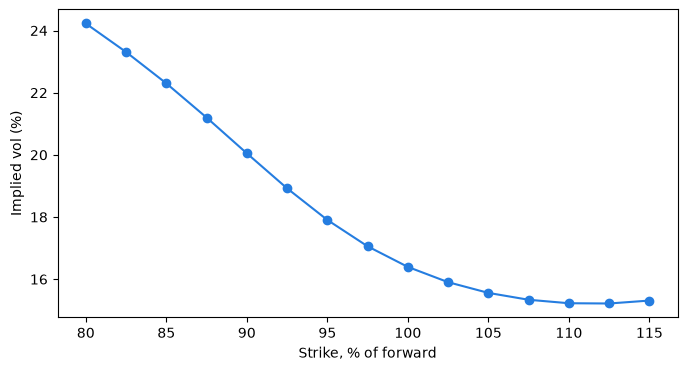

In [7]:
cp = SCENARIOS['crash_prone']
T = 0.25
F = S0 * np.exp(r * T)
mny = np.linspace(0.8, 1.15, 15)
ivs = []
for x in mny:
    K = F * x
    kind = 'put' if x < 1 else 'call'
    price = merton_price(S0, K, T, r, cp.sigma, kind=kind, **cp.jumps)
    ivs.append(implied_vol(price, S0, K, T, r, kind=kind))
plt.figure(figsize=(8,4))
plt.plot(mny * 100, np.array(ivs) * 100, marker='o', color='#257de0')
plt.xlabel('Strike, % of forward'); plt.ylabel('Implied vol (%)'); plt.show()

Out-of-the-money puts carry higher implied volatility than calls: the same downward skew Project 1 found in real SPX quotes, which a single-volatility Black-Scholes model cannot produce.